In [6]:
import json
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "textstyle").is_dir())
sys.path.insert(0, str(ROOT))
import matplotlib.pyplot as plt
import pandas as pd
import torch
from IPython.display import Image, display
from sklearn.metrics import auc, roc_curve

from textstyle.data import load_splits, read_corpus, verify_splits
from textstyle.evaluation import collect_logits, metrics_from_logits
from textstyle.models import build_model
from textstyle.predict import Predictor
from textstyle.settings import STYLES, TONES
from textstyle.tokenization import Collator, TextDataset, Vocabulary, tokenize
from textstyle.train import make_loader, train_experiment

torch.set_num_threads(2)
print("Python:", sys.version.split()[0], "PyTorch:", torch.__version__)
print("CUDA:", torch.cuda.is_available())

%matplotlib inline

Python: 3.12.10 PyTorch: 2.8.0+cpu
CUDA: False


## Предметна область та постановка задачі

Діловий стиль описує спосіб написання повідомлення, а терміновий тон — його емоційне або комунікативне забарвлення. Один текст може бути діловим і дружнім або офіційним і саркастичним. Тому не об'єднуємо 25 комбінацій в один клас, а оптимізуємо дві багатокласові задачі зі спільним представленням тексту. В кожній задачі є п'ять взаємовиключних міток.

Гіпотеза дослідження: локальні мовні звороти CNN, послідовність слів BiLSTM та контекстні представлення DistilBERT можуть розрізняти ці класи. Перевагу будь-якої архітектури потрібно перевірити на однакових даних, а не припускати заздалегідь.

In [7]:
raw = pd.read_csv(ROOT / "data/raw/dataset.csv", keep_default_na=False)
print("Розмір вихідного CSV:", raw.shape)
display(raw[["text", "style", "tone"]].head())
display(pd.DataFrame({"missing": raw.isna().sum(), "empty_strings": raw.astype(str).eq("").sum()}))

Розмір вихідного CSV: (1000, 4)


,text,style,tone
0,"The sheer, unadulterated arrogance required to...",academic,aggressive
1,It is entirely baffling how an executive manag...,business,aggressive
2,Your team has aggressively managed to complete...,business,aggressive
3,Synergy is just a fancy word for doing all the...,business,sarcastic
4,Contemporary linguistic theories frequently ex...,academic,neutral


,missing,empty_strings
text,0,0
clean_text,0,0
style,0,0
tone,0,0


## Аналіз даних

Перевіряємо баланс класів, довжини уривків, перетин стилів і тонів. Однаковий баланс класів сам по собі не забезпечує репрезентативність для реальної мови.

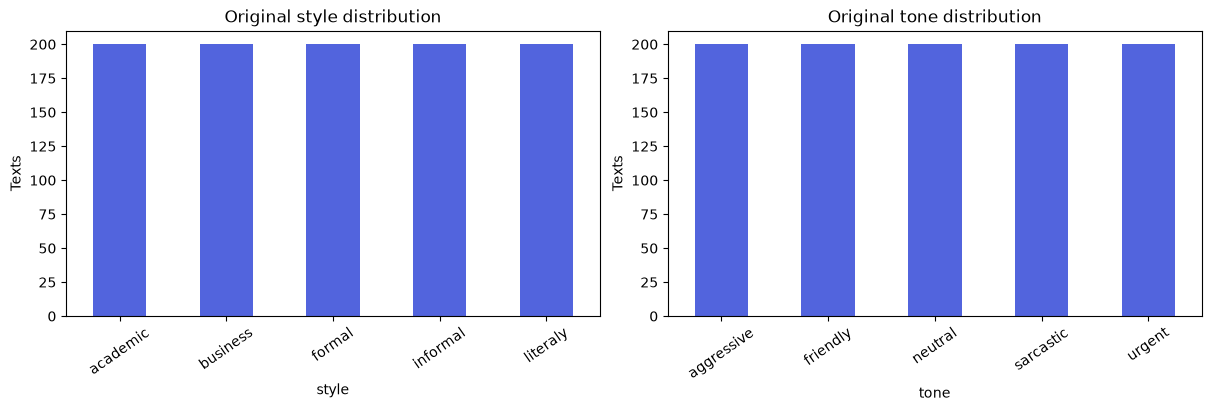

tone,aggressive,friendly,neutral,sarcastic,urgent
style,,,,,
academic,40,40,40,40,40
business,40,40,40,40,40
formal,40,40,40,40,40
informal,40,40,40,40,40
literaly,40,40,40,40,40


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for ax, column in zip(axes, ["style", "tone"], strict=True):
    raw[column].value_counts().sort_index().plot.bar(ax=ax, color="#5264dd")
    ax.set(title=f"Original {column} distribution", ylabel="Texts")
    ax.tick_params(axis="x", rotation=35)
plt.show()
display(pd.crosstab(raw["style"], raw["tone"]))

In [ ]:
lengths = raw.text.str.len()
display(lengths.describe().to_frame("Characters"))
fig, ax = plt.subplots(figsize=(10, 3.5), constrained_layout=True)
ax.hist(lengths, bins=25, color="#5264dd", edgecolor="white")
ax.set(xlabel="Characters", ylabel="Texts", title="Text length distribution")
plt.show()